In [1]:
%pip install plotly kaleido

  Attempting uninstall: platformdirs
    Found existing installation: platformdirs 3.10.0
    Uninstalling platformdirs-3.10.0:
      Successfully uninstalled platformdirs-3.10.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path

print("BROKE — Data Visualization Started!")

BROKE — Data Visualization Started!


In [3]:
COLORS = {
    "background": "#0F1020",
    "card": "#1A1B2E",
    "purple": "#A78BFA",
    "mint": "#6EE7B7",
    "pink": "#F472B6",
    "white": "#F8FAFC"
}

In [5]:
def style_chart(fig, title):

    fig.update_layout(
        title={
            "text": title,
            "x": 0.5,
            "xanchor": "center"
        },
        paper_bgcolor=COLORS["background"],
        plot_bgcolor=COLORS["background"],
        font=dict(
            family="Arial",
            color=COLORS["white"],
            size=13
        ),
        title_font_size=20,
        margin=dict(l=40, r=40, t=90, b=50),
        hovermode="closest"
    )

    return fig

In [7]:
df = pd.read_csv(
    "../data/processed/cleaned_student_expenses.csv",
    parse_dates=["date"]
)

student_summary = pd.read_csv(
    "../data/processed/student_behavioral_summary.csv"
)

student_daily = pd.read_csv(
    "../data/processed/student_daily_spending.csv",
    parse_dates=["date"]
)

print("Transactions:", len(df))
print("Students:", df["student_id"].nunique())

Transactions: 7565
Students: 100


In [9]:
print("Transactions columns:")
print(df.columns.tolist())

print("\nStudent summary columns:")
print(student_summary.columns.tolist())

print("\nDaily spending columns:")
print(student_daily.columns.tolist())

Transactions columns:
['student_id', 'date', 'category', 'amount_tnd', 'payment_method', 'is_essential', 'monthly_budget', 'city', 'day_of_week', 'is_weekend', 'expense_size']

Student summary columns:
['student_id', 'total_spending', 'monthly_budget', 'city', 'transactions', 'remaining_budget', 'over_budget', 'small_budget_share', 'personality', 'first_over_budget_date']

Daily spending columns:
['student_id', 'date', 'amount_tnd', 'cumulative_spending', 'monthly_budget', 'budget_used_pct']


In [11]:
category_spending = (
    df.groupby("category", as_index=False)["amount_tnd"]
    .sum()
    .sort_values("amount_tnd", ascending=True)
)

category_spending

,category,amount_tnd
0,Coffee,5913.89
5,Transport,6754.15
3,Food,15053.69
2,Entertainment,28439.43
1,Education,34951.68
4,Shopping,72337.63


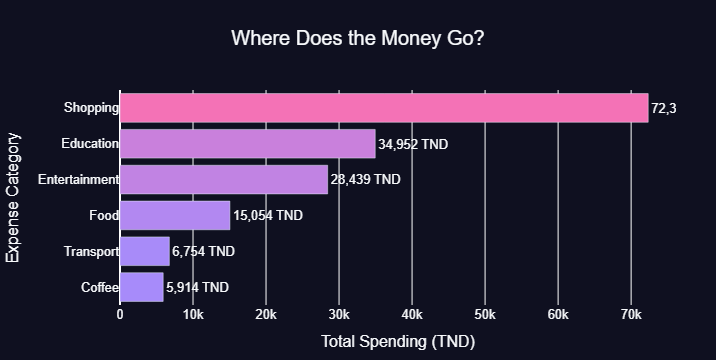

In [13]:
fig1 = px.bar(
    category_spending,
    x="amount_tnd",
    y="category",
    orientation="h",
    text="amount_tnd",
    color="amount_tnd",
    color_continuous_scale=[
        COLORS["purple"],
        COLORS["pink"]
    ],
    labels={
        "amount_tnd": "Total Spending (TND)",
        "category": "Expense Category"
    }
)

fig1.update_traces(
    texttemplate="%{text:,.0f} TND",
    textposition="outside"
)

fig1.update_layout(
    coloraxis_showscale=False
)

fig1 = style_chart(
    fig1,
    "Where Does the Money Go?"
)

fig1.show()

In [15]:
%pip install --upgrade "plotly>=6.1.1"

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
  Attempting uninstall: plotly
    Found existing installation: plotly 5.24.1
    Uninstalling plotly-5.24.1:
      Successfully uninstalled plotly-5.24.1
Note: you may need to restart the kernel to use updated packages.


In [15]:
small_expenses = df[
    df["amount_tnd"] < 10
].copy()

In [17]:
small_daily = (
    small_expenses.groupby("date", as_index=False)["amount_tnd"]
    .sum()
    .sort_values("date")
)

small_daily["cumulative_small_spending"] = (
    small_daily["amount_tnd"].cumsum()
)

small_daily.head()

,date,amount_tnd,cumulative_small_spending
0,2026-09-01,614.02,614.02
1,2026-09-02,633.37,1247.39
2,2026-09-03,604.57,1851.96
3,2026-09-04,701.86,2553.82
4,2026-09-05,610.69,3164.51


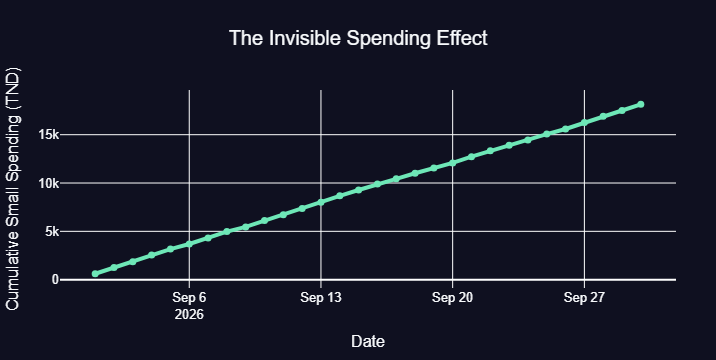

In [21]:
fig2 = px.line(
    small_daily,
    x="date",
    y="cumulative_small_spending",
    markers=True,
    labels={
        "date": "Date",
        "cumulative_small_spending":
            "Cumulative Small Spending (TND)"
    }
)

fig2.update_traces(
    line=dict(
        color=COLORS["mint"],
        width=4
    ),
    marker=dict(size=7)
)

fig2 = style_chart(
    fig2,
    " The Invisible Spending Effect"
)

fig2.show()

In [23]:
selected_student = "S001"

student_small = df[
    (df["student_id"] == selected_student) &
    (df["amount_tnd"] < 10)
].copy()

student_small_daily = (
    student_small.groupby("date", as_index=False)["amount_tnd"]
    .sum()
    .sort_values("date")
)

student_small_daily["cumulative"] = (
    student_small_daily["amount_tnd"].cumsum()
)

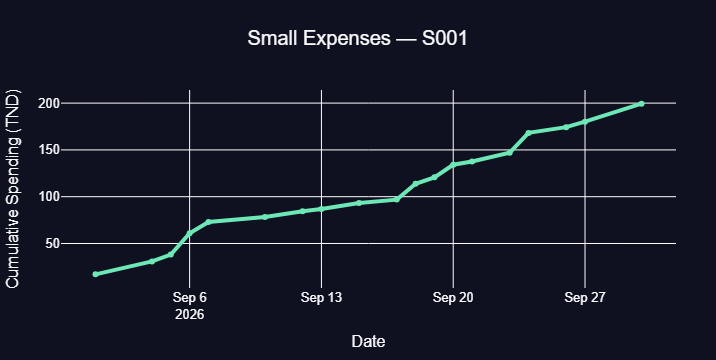

In [29]:
fig2_student = px.line(
    student_small_daily,
    x="date",
    y="cumulative",
    markers=True,
    labels={
        "date": "Date",
        "cumulative": "Cumulative Spending (TND)"
    }
)

fig2_student.update_traces(
    line_color=COLORS["mint"],
    line_width=4
)

fig2_student = style_chart(
    fig2_student,
    f" Small Expenses — {selected_student}"
)

fig2_student.show()

In [31]:
selected_student = "S001"

student_budget_data = student_daily[
    student_daily["student_id"] == selected_student
].copy()

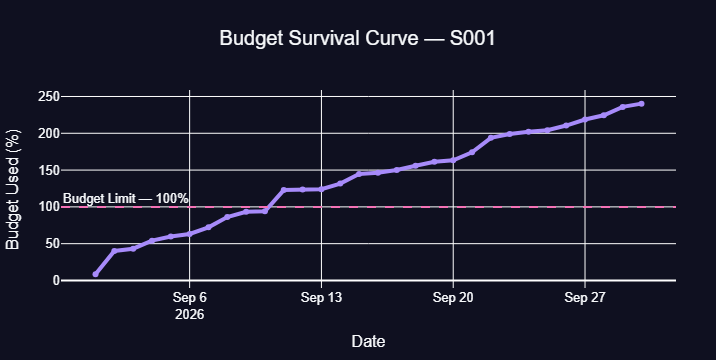

In [33]:
fig3 = go.Figure()

fig3.add_trace(
    go.Scatter(
        x=student_budget_data["date"],
        y=student_budget_data["budget_used_pct"],
        mode="lines+markers",
        name="Budget Used",
        line=dict(
            color=COLORS["purple"],
            width=4
        )
    )
)

fig3.add_hline(
    y=100,
    line_dash="dash",
    line_color=COLORS["pink"],
    annotation_text="Budget Limit — 100%",
    annotation_position="top left"
)

fig3.update_layout(
    xaxis_title="Date",
    yaxis_title="Budget Used (%)"
)

fig3 = style_chart(
    fig3,
    f" Budget Survival Curve — {selected_student}"
)

fig3.show()

In [35]:
daily_total = (
    df.groupby("date", as_index=False)["amount_tnd"]
    .sum()
)

daily_total["day_type"] = np.where(
    daily_total["date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

In [37]:
weekend_comparison = (
    daily_total.groupby("day_type", as_index=False)["amount_tnd"]
    .mean()
)

weekend_comparison

,day_type,amount_tnd
0,Weekday,5469.856818
1,Weekend,5389.202500


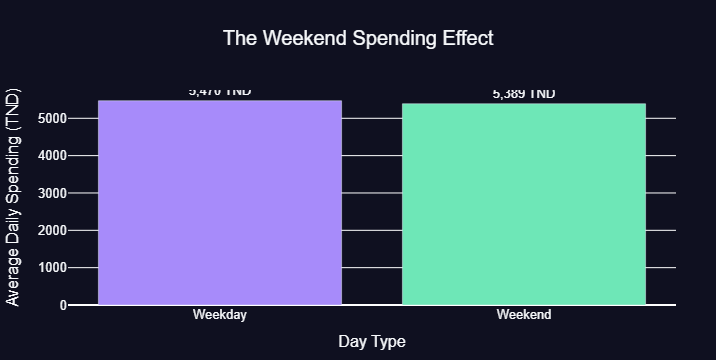

In [39]:
fig4 = px.bar(
    weekend_comparison,
    x="day_type",
    y="amount_tnd",
    color="day_type",
    text="amount_tnd",
    color_discrete_map={
        "Weekday": COLORS["purple"],
        "Weekend": COLORS["mint"]
    },
    labels={
        "day_type": "Day Type",
        "amount_tnd": "Average Daily Spending (TND)"
    }
)

fig4.update_traces(
    texttemplate="%{text:,.0f} TND",
    textposition="outside"
)

fig4.update_layout(
    showlegend=False
)

fig4 = style_chart(
    fig4,
    "The Weekend Spending Effect"
)

fig4.show()

In [41]:
personality_counts = (
    student_summary["personality"]
    .value_counts()
    .reset_index()
)

personality_counts.columns = [
    "personality",
    "count"
]

personality_counts

,personality,count
0,Shopping Enthusiast,65
1,Balanced Spender,34
2,Entertainment Lover,1


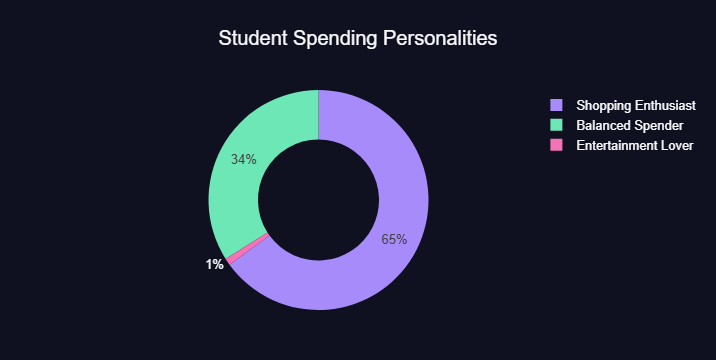

In [43]:
fig5 = px.pie(
    personality_counts,
    names="personality",
    values="count",
    hole=0.55,
    color_discrete_sequence=[
        COLORS["purple"],
        COLORS["mint"],
        COLORS["pink"],
        "#FBBF24",
        "#60A5FA"
    ]
)

fig5.update_traces(
    textinfo="percent",
    hovertemplate=(
        "%{label}<br>"
        "Students: %{value}<br>"
        "Share: %{percent}<extra></extra>"
    )
)

fig5 = style_chart(
    fig5,
    " Student Spending Personalities"
)

fig5.show()

In [47]:
total_spending = df["amount_tnd"].sum()

small_spending = df.loc[
    df["amount_tnd"] < 10,
    "amount_tnd"
].sum()

small_share = (
    small_spending / total_spending * 100
)

top_category = (
    df.groupby("category")["amount_tnd"]
    .sum()
    .idxmax()
)

over_budget_share = (
    student_summary["total_spending"]
    > student_summary["monthly_budget"]
).mean() * 100

print(" BROKE — KEY INSIGHTS")
print("-" * 40)

print(
    f"1. The largest spending category "
    f"is {top_category}."
)

print(
    f"2. Small transactions represent "
    f"{small_share:.1f}% of total spending."
)

print(
    f"3. {over_budget_share:.1f}% of simulated "
    f"students exceeded their monthly budget."
)

print("-" * 40)
print("Note: Results are based on synthetic data.")

 BROKE — KEY INSIGHTS
----------------------------------------
1. The largest spending category is Shopping.
2. Small transactions represent 11.1% of total spending.
3. 100.0% of simulated students exceeded their monthly budget.
----------------------------------------
Note: Results are based on synthetic data.


In [49]:
images_dir = Path("../images")

images_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [51]:
fig1.write_image(
    "../images/spending_categories.png",
    width=1200,
    height=700
)

fig2.write_image(
    "../images/invisible_spending.png",
    width=1200,
    height=700
)

fig3.write_image(
    "../images/budget_survival.png",
    width=1200,
    height=700
)

fig4.write_image(
    "../images/weekend_effect.png",
    width=1200,
    height=700
)

fig5.write_image(
    "../images/spending_personalities.png",
    width=1200,
    height=700
)

print("All charts exported successfully!")

All charts exported successfully!


In [53]:
fig1.write_html(
    "../images/spending_categories.html"
)